# Example usage of spectraxai for modeling

Using various pre-processing techniques, models and splitting methods

## Load the example dataset

In [1]:
from spectraxai.data import load_GR_SSL

dataset = load_GR_SSL()

## Kennard-Stone split and PLS

In [2]:
from spectraxai.dataset import DatasetSplit

idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.KENNARD_STONE, 0.8)

2026-11-15 09:37:48,057 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



2026-11-15 09:37:48,061 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



In [3]:
from spectraxai.models import Model, StandardModel
from spectraxai.utils import metrics 

pls = StandardModel(Model.PLS)

datasetTrn, datasetTst = dataset.subset(idx_trn), dataset.subset(idx_tst)
pls.fit(datasetTrn)
y_hat = pls.predict(datasetTst.X)
metrics(datasetTst.Y, y_hat)

{'N': 186,
 'RMSE': 0.3458105757011216,
 'R2': 0.6369625596758561,
 'RPIQ': np.float64(2.5302869879729997)}

**Note:** The above may also be simplified with a single call as follows:

In [4]:
pls.fit_and_predict(dataset, idx_trn=idx_trn)

,N,RMSE,R2,RPIQ,output,pre_process,val_score,model_name,best_hyperparameters,n_components,feature_importance,importance_method,random_state,training_time,testing_time
0,186,0.345811,0.636963,2.530287,OM,NONE,0.503412,PLS,{'n_components': 16},16,"[2.233024, 1.987569, 1.509694, 1.385415, 1.124...",VIP,None,0.906994,0.000158


## cross-validation split and RF with ABS + SG1 transformation

In [5]:
from spectraxai.spectra import SpectralPreprocessing

preprocess = [
    SpectralPreprocessing.ABS,
    (SpectralPreprocessing.SG1, {"window_length": 7, "polyorder": 3})
]

idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.CROSS_VALIDATION, 5, random_state=0)

rf = StandardModel(Model.RF, random_state=0)
rf.fit_and_predict(dataset, preprocess=preprocess, idx_trn=idx_trn)

,N,RMSE,R2,RPIQ,output,pre_process,val_score,model_name,best_hyperparameters,max_features,n_estimators,feature_importance,importance_method,random_state,training_time,testing_time,fold
0,186,0.412263,0.477389,1.989020,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.487419,RF,"{'max_features': 'sqrt', 'n_estimators': 100}",sqrt,100,"[0.005667, 0.00643, 0.009244, 0.007512, 0.0129...",impurity,0,5.889060,0.004340,1
1,186,0.485648,0.472023,1.781127,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.488271,RF,"{'max_features': 'sqrt', 'n_estimators': 200}",sqrt,200,"[0.00672, 0.005899, 0.005463, 0.005777, 0.0104...",impurity,0,5.468208,0.008638,2
2,186,0.434979,0.562652,1.834571,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.438645,RF,"{'max_features': 'sqrt', 'n_estimators': 150}",sqrt,150,"[0.007734, 0.006954, 0.007062, 0.006597, 0.014...",impurity,0,6.831411,0.007269,3
3,185,0.459966,0.515793,1.739259,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.428455,RF,"{'max_features': 'sqrt', 'n_estimators': 50}",sqrt,50,"[0.004029, 0.003327, 0.005792, 0.005718, 0.006...",impurity,0,6.321215,0.002657,4
4,185,0.367018,0.588029,2.234222,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.439791,RF,"{'max_features': 'sqrt', 'n_estimators': 200}",sqrt,200,"[0.00665, 0.006344, 0.007945, 0.007792, 0.0124...",impurity,0,6.552881,0.008603,5


## cross-validation split and SVR with different pre-treatments and custom grid search

In [6]:
import numpy as np

from spectraxai.spectra import SpectralPreprocessing


preprocesses = [
    [
        SpectralPreprocessing.ABS,
        (SpectralPreprocessing.SG1, {"window_length": 7, "polyorder": 3})
    ],
    [
        SpectralPreprocessing.ABS,
        SpectralPreprocessing.CR
    ],
    SpectralPreprocessing.SNV
]

idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.CROSS_VALIDATION, 5, random_state=0)

svr_params = {
    "epsilon": [0.01, 0.05, 0.1],
    "C": np.logspace(start=-1, stop=7, base=2, num=9),
}

svr = StandardModel(Model.SVR, grid_search_hyperparameters=svr_params, random_state=0)
svr.fit_and_predict_multiple(dataset, preprocesses=preprocesses, idx_trn=idx_trn)

,N,RMSE,R2,RPIQ,output,pre_process,val_score,model_name,best_hyperparameters,C,epsilon,gamma,SVs,feature_importance,importance_method,random_state,training_time,testing_time,fold
0,186,0.369140,0.581002,2.221380,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.563135,SVR,"{'C': 16.0, 'epsilon': 0.05, 'gamma': 0.002023...",16.0,0.05,0.002024,637,None,None,0,4.276394,0.009191,1
1,186,0.455309,0.535929,1.899809,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.574158,SVR,"{'C': 8.0, 'epsilon': 0.01, 'gamma': 0.0016323...",8.0,0.01,0.001632,721,None,None,0,4.723082,0.012383,2
2,186,0.367159,0.688399,2.173446,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.524691,SVR,"{'C': 16.0, 'epsilon': 0.1, 'gamma': 0.0016306...",16.0,0.10,0.001631,566,None,None,0,4.127353,0.007602,3
3,185,0.417829,0.600444,1.914659,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.546268,SVR,"{'C': 16.0, 'epsilon': 0.01, 'gamma': 0.001371...",16.0,0.01,0.001372,721,None,None,0,4.121665,0.009630,4
4,185,0.334374,0.658055,2.452345,OM,"[absorbance, (SG1, {'window_length': 7, 'polyo...",0.521063,SVR,"{'C': 8.0, 'epsilon': 0.05, 'gamma': 0.0019092...",8.0,0.05,0.001909,649,None,None,0,3.799288,0.009177,5
5,186,0.395732,0.518461,2.072110,OM,"[absorbance, continuum-removal]",0.503873,SVR,"{'C': 16.0, 'epsilon': 0.1, 'gamma': 0.0019272...",16.0,0.10,0.001927,570,None,None,0,4.023296,0.007639,1
6,186,0.475520,0.493815,1.819063,OM,"[absorbance, continuum-removal]",0.500204,SVR,"{'C': 2.0, 'epsilon': 0.1, 'gamma': 0.00840054...",2.0,0.10,0.008401,571,None,None,0,3.925465,0.007852,2
7,186,0.449080,0.533837,1.776966,OM,"[absorbance, continuum-removal]",0.479717,SVR,"{'C': 4.0, 'epsilon': 0.1, 'gamma': 0.01446149...",4.0,0.10,0.014461,563,None,None,0,4.287687,0.007555,3
8,185,0.442901,0.551055,1.806274,OM,"[absorbance, continuum-removal]",0.479140,SVR,"{'C': 8.0, 'epsilon': 0.1, 'gamma': 0.00164544...",8.0,0.10,0.001645,561,None,None,0,4.502248,0.007701,4
9,185,0.354255,0.616184,2.314716,OM,"[absorbance, continuum-removal]",0.460052,SVR,"{'C': 4.0, 'epsilon': 0.1, 'gamma': 0.00803691...",4.0,0.10,0.008037,568,None,None,0,4.608197,0.008069,5


## Comparing models

Every row of `fit_and_predict` has the same columns, so results of different models can be concatenated and compared directly. `best_hyperparameters` holds all tuned hyperparameters and `importance_method` says how `feature_importance` was obtained.

In [7]:
import pandas as pd

idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.KENNARD_STONE, 0.8)
models = [Model.PLS, Model.RIDGE, Model.ELASTIC_NET, Model.GPR]
results = pd.concat(
    [StandardModel(m, random_state=0).fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn) for m in models],
    ignore_index=True,
)
results[["model_name", "RMSE", "R2", "RPIQ", "importance_method", "best_hyperparameters"]]

2026-11-15 09:39:33,738 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



2026-11-15 09:39:33,745 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.478172e+01, tolerance: 2.264e-02
  model = cd_fast.enet_coordinate_descent(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.900621e+01, tolerance: 2.427e-02
  model = cd_fast.enet_coordinate_descent(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the

/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.391385e+01, tolerance: 2.264e-02
  model = cd_fast.enet_coordinate_descent(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.938575e+01, tolerance: 2.527e-02
  model = cd_fast.enet_coordinate_descent(


/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.835665e+01, tolerance: 2.427e-02
  model = cd_fast.enet_coordinate_descent(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.149089e+01, tolerance: 2.465e-02
  model = cd_fast.enet_coordinate_descent(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the

/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.729528e+01, tolerance: 2.527e-02
  model = cd_fast.enet_coordinate_descent(


... (5 outputs left out)

/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.137477e+01, tolerance: 3.051e-02
  model = cd_fast.enet_coordinate_descent(


/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  w

/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,model_name,RMSE,R2,RPIQ,importance_method,best_hyperparameters
0,PLS,0.341458,0.646044,2.562540,VIP,{'n_components': 16}
1,RIDGE,0.339190,0.650731,2.579676,coef,{'alpha': 0.1}
2,ELASTIC_NET,0.343106,0.642619,2.550231,coef,"{'alpha': 0.0001, 'l1_ratio': 0.1}"
3,GPR,0.338601,0.651942,2.584160,None,{}


## Bring your own estimator

Any scikit-learn regressor can be used with `Model.CUSTOM`; it is cloned, never modified.

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = StandardModel(
    Model.CUSTOM,
    estimator=HistGradientBoostingRegressor(random_state=0),
    grid_search_hyperparameters={"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31]},
)
hgb.fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn)[["model_name", "RMSE", "R2", "best_hyperparameters"]]

,model_name,RMSE,R2,best_hyperparameters
0,CUSTOM,0.440771,0.410205,"{'learning_rate': 0.05, 'max_leaf_nodes': 15}"


## Stateful pre-processing

MSC and mean-centering learn a reference spectrum. In `fit_and_predict` it is learnt from the training samples only, so the test samples never influence it.

In [9]:
pls.fit_and_predict(dataset, [SpectralPreprocessing.ABS, SpectralPreprocessing.MSC], idx_trn=idx_trn)[["pre_process", "RMSE", "R2"]]

,pre_process,RMSE,R2
0,"[absorbance, MSC]",0.348727,0.630814


## scikit-learn pipelines

`StandardModel` is a scikit-learn regressor and `SpectralPreprocessor` a transformer, so they compose with pipelines, `cross_val_score`, `GridSearchCV`, etc.

In [10]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

from spectraxai.preprocessing import SpectralPreprocessor

pipe = make_pipeline(
    SpectralPreprocessor([SpectralPreprocessing.ABS, SpectralPreprocessing.SNV]),
    StandardModel(Model.PLS, init_hyperparameters={"n_components": 10}),
)
cross_val_score(pipe, dataset.X, dataset.Y.ravel(), cv=5).round(3)

array([-0.005,  0.473,  0.539,  0.554,  0.452])

## Random and Bayesian hyperparameter search

Instead of every combination of a grid, `search="random"` or `search="bayes"` tries `n_iter` candidates from continuous ranges (the defaults cover each model's grid). Bayesian search (Optuna, `pip install spectraxai[optuna]`) proposes each candidate from the previous results and stops unpromising ones early; `search_results_` lists every candidate.

In [11]:
svr = StandardModel(Model.SVR, search="bayes", n_iter=30, random_state=0)
svr.fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn)[["RMSE", "R2", "C", "epsilon", "gamma"]]

/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,RMSE,R2,C,epsilon,gamma
0,0.35149,0.624941,180.599932,0.069413,0.002232


In [12]:
svr.search_results_.sort_values("rank_test_score").head()

,param_C,param_epsilon,param_gamma,mean_test_score,std_test_score,n_folds,state,rank_test_score
21,180.599932,0.069413,0.002232,0.461281,0.109959,5,complete,1
26,213.604387,0.116491,0.001970,0.460094,0.128183,5,complete,2
19,124.377608,0.082834,0.002468,0.457426,0.107065,5,complete,3
17,144.297981,0.081047,0.001727,0.454622,0.115466,5,complete,4
20,207.972001,0.071880,0.002336,0.447746,0.135338,5,complete,5


## Searching pre-processing and model together

`PreprocessingSearch` explores pre-processings, models and their hyperparameters in one search. Options written as ranges, such as the fractional derivative order below, are tuned too. Every candidate is cross-validated as a whole pipeline (stateful steps never see the validation folds), and the best pipeline is refitted on the training set.

In [13]:
from spectraxai.search import PreprocessingSearch

SP = SpectralPreprocessing
search = PreprocessingSearch(
    models=[Model.PLS, Model.RIDGE],
    preprocessings=[
        SP.ABS,
        [SP.ABS, SP.SNV],
        [SP.ABS, (SP.FD, {"order": ("float", 0.0, 2.0)})],
    ],
    n_iter=40,
    random_state=0,
).fit(dataset.subset(idx_trn))
print(search.best_params_)
metrics(dataset.Y[idx_tst], search.predict(dataset.X[idx_tst]))

{'preprocessing': absorbance, 'model': 'RIDGE', 'hyperparameters': {'alpha': 0.02746337820929304}}


{'N': 186,
 'RMSE': 0.33620106752437634,
 'R2': 0.656858653683965,
 'RPIQ': np.float64(2.602609225613354)}

In [14]:
search.results_.sort_values("rank_test_score")[["preprocessing", "model", "hyperparameters", "mean_test_score", "state"]].head()

,preprocessing,model,hyperparameters,mean_test_score,state
39,ABS,RIDGE,{'alpha': 0.02746337820929304},0.526567,complete
38,ABS,RIDGE,{'alpha': 0.025987489784704738},0.526312,complete
36,ABS,RIDGE,{'alpha': 0.021224711037660448},0.525373,complete
37,ABS,RIDGE,{'alpha': 0.019668570733366936},0.525023,complete
33,ABS,RIDGE,{'alpha': 0.014062602513224668},0.523540,complete


## Local models (memory-based learning)

`Model.LOCAL_PLS` and `Model.LOCAL_GPR` keep the training spectra in memory and predict each new spectrum with a model fitted on its `k` most similar training spectra only, as the R package resemble does. Neighbours are found by the Mahalanobis distance in principal-component space (or by correlation, `metric="correlation"`). Local models pay off most in large, diverse spectral libraries where the relation between spectrum and property changes across the library; on this small dataset the gain over global PLS is modest, and prediction is slower since a model is fitted per neighbourhood. `k` and `n_components` (or `noise_variance` for GPR) are searched like any other hyperparameters.

In [15]:
idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.KENNARD_STONE, 0.8)
local = {m: StandardModel(m) for m in (Model.PLS, Model.LOCAL_PLS, Model.LOCAL_GPR)}
results = pd.concat(
    [sm.fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn) for sm in local.values()],
    ignore_index=True,
)
results[["model_name", "RMSE", "R2", "RPIQ", "best_hyperparameters", "training_time", "testing_time"]]

2026-11-15 09:39:51,766 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



2026-11-15 09:39:51,770 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



,model_name,RMSE,R2,RPIQ,best_hyperparameters,training_time,testing_time
0,PLS,0.341458,0.646044,2.562540,{'n_components': 16},1.078564,0.000195
1,LOCAL_PLS,0.329064,0.671273,2.659058,"{'k': 200, 'n_components': 10}",1.483727,0.176607
2,LOCAL_GPR,0.326594,0.676189,2.679167,"{'k': 200, 'noise_variance': 0.1}",2.122231,0.197684


Each local PLS model has its own VIP scores. `LocalPLSRegressor.vip(X)` averages them over the local models that predict `X`, here the test spectra, to compare with the VIP of the global model.

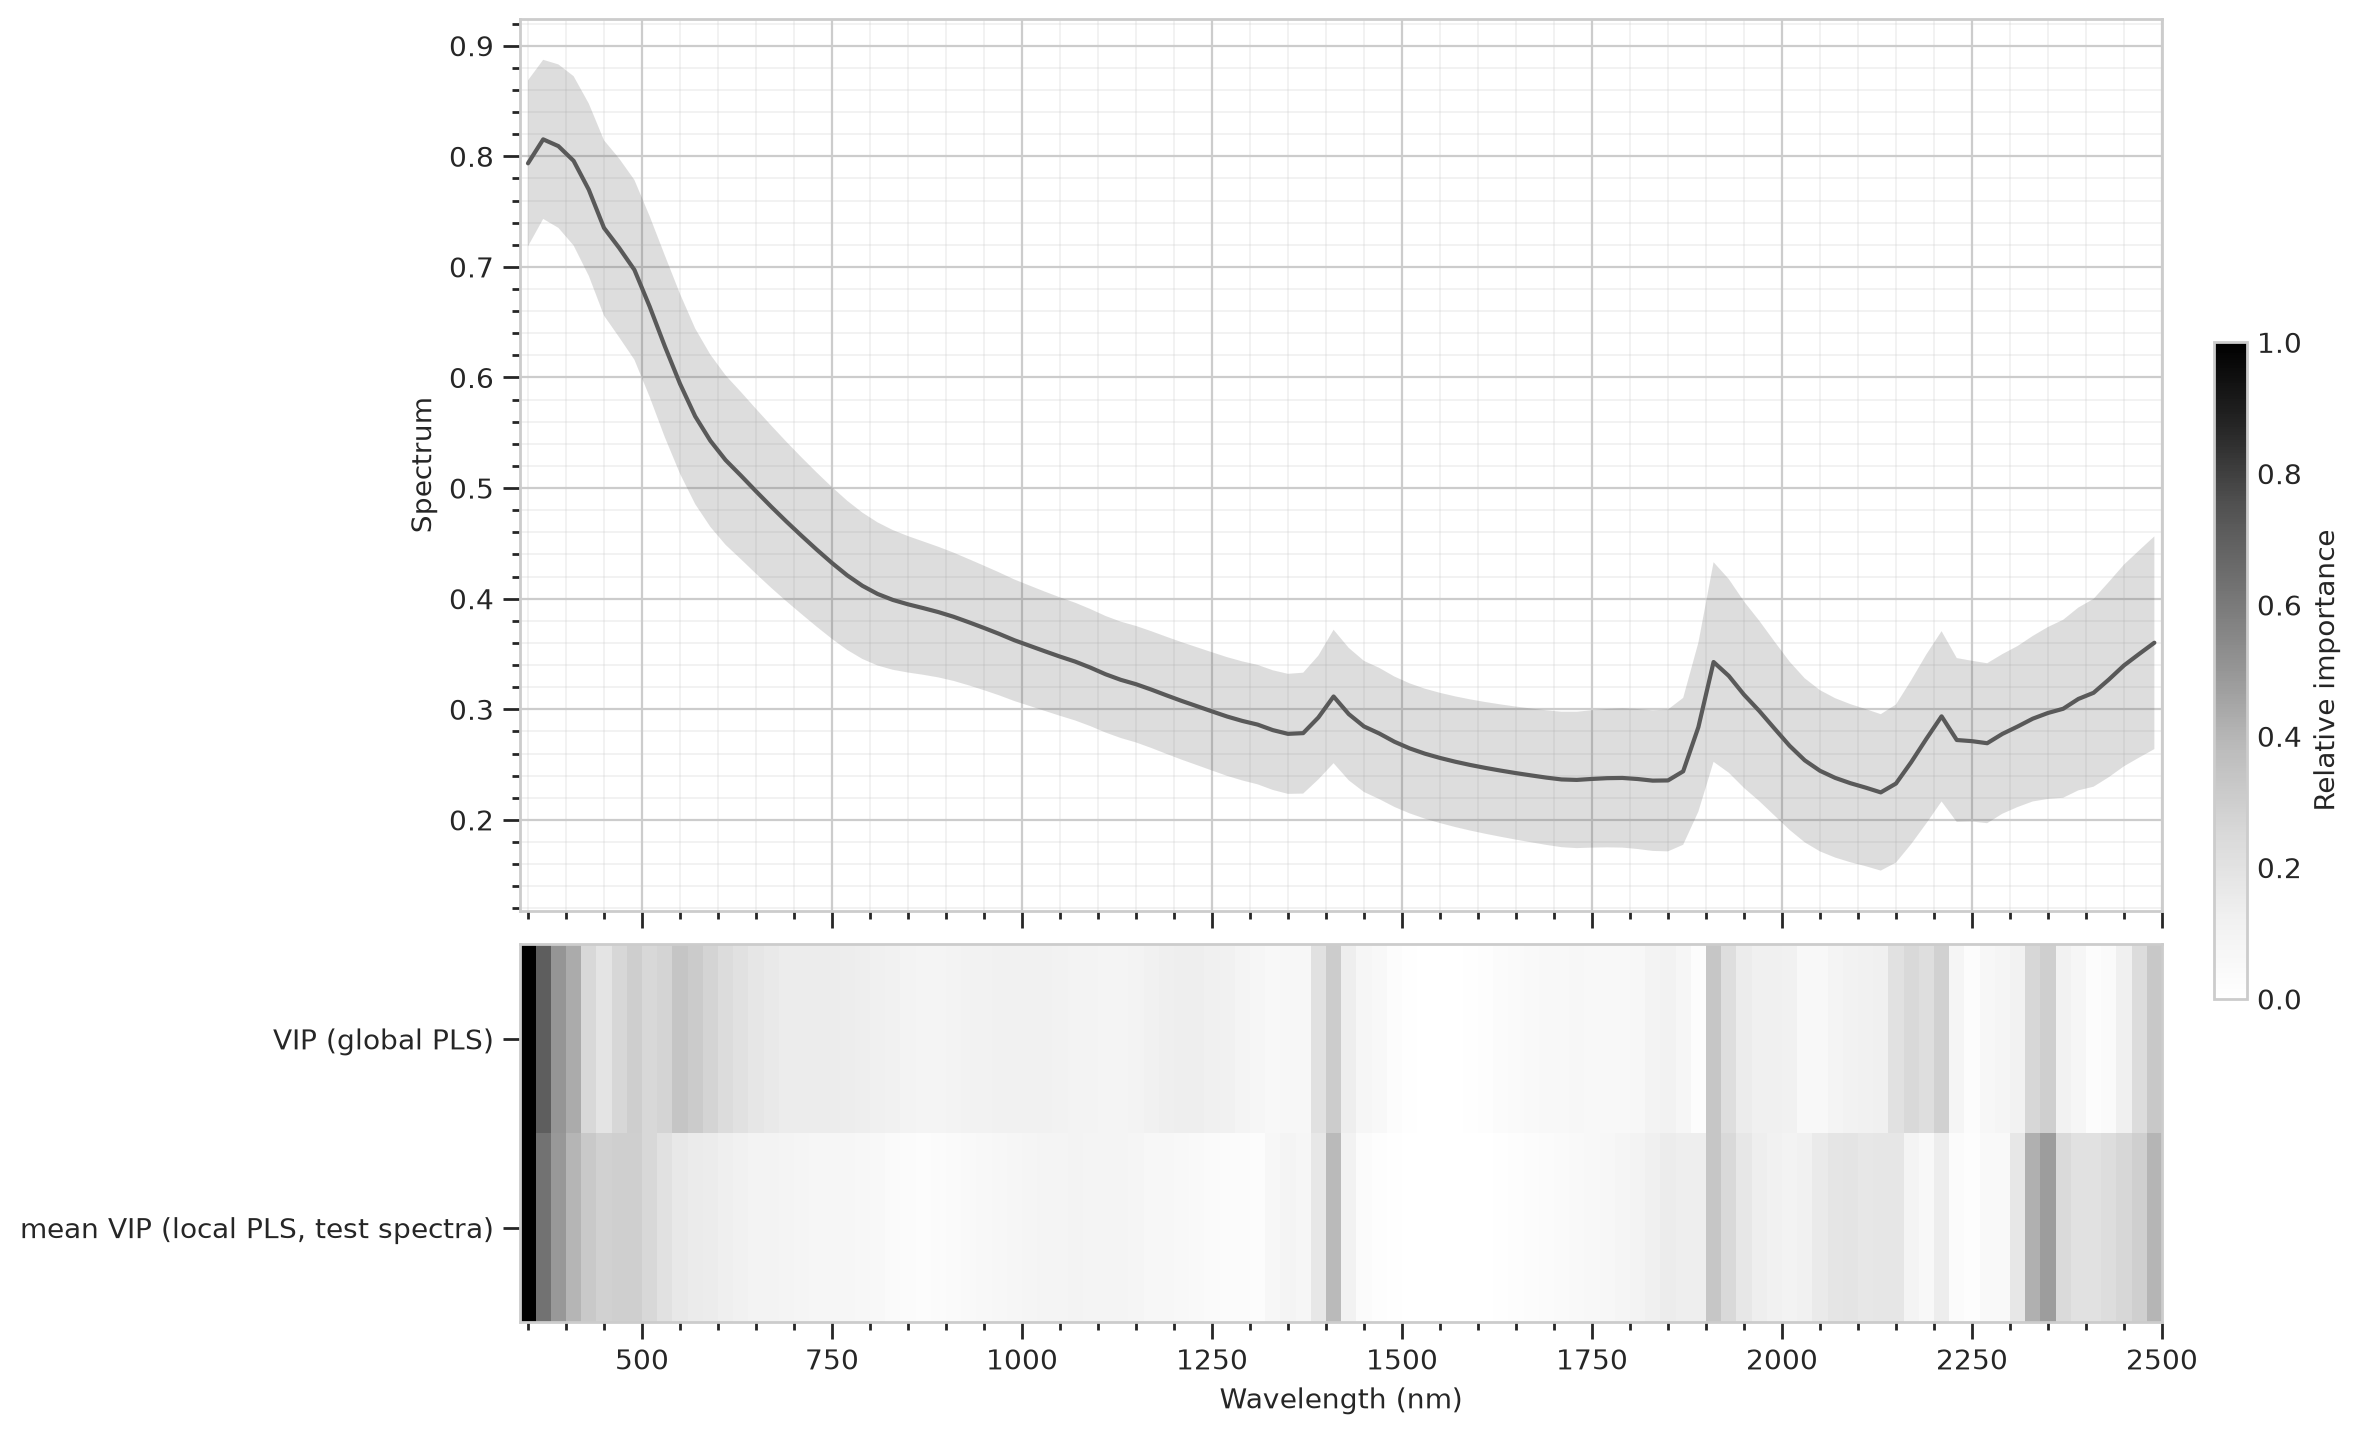

In [16]:
from spectraxai.explain import PreHocAnalysis

absorbance = dataset.preprocess(SpectralPreprocessing.ABS)
local_pls = local[Model.LOCAL_PLS].best_model
ax = PreHocAnalysis(absorbance).plot_importance_strip(
    {
        "VIP (global PLS)": local[Model.PLS].feature_importance()[0],
        "mean VIP (local PLS, test spectra)": local_pls.vip(absorbance.X[idx_tst]),
    },
    with_spectrum=True,
    colorbar=True,
)

### Choosing the neighbours

How the nearest training spectra are found is set with `dissimilarity`, a `Dissimilarity` member from `spectraxai.dissimilarity`: distances of the spectra or of their principal-component or PLS scores, correlation, or the spectral angle (`SAM`), the spectral information divergence (`SID`) and their combinations (`SID_SAM_TAN`, `SID_SAM_SIN`). `SpectralDissimilarity` sets their options (e.g. the number of components) and computes the matrices on their own. The dissimilarity can also be searched like any other hyperparameter.

In [17]:
from spectraxai.dissimilarity import Dissimilarity, SpectralDissimilarity

measures = [
    Dissimilarity.PCA_MAHALANOBIS,
    SpectralDissimilarity(Dissimilarity.PCA_EUCLIDEAN, n_components=10),
    Dissimilarity.CORRELATION,
    Dissimilarity.SAM,
    Dissimilarity.SID,
    Dissimilarity.SID_SAM_TAN,
]
rows = []
for measure in measures:
    sm = StandardModel(Model.LOCAL_PLS, init_hyperparameters={"k": 200, "n_components": 10, "dissimilarity": measure})
    res = sm.fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn)
    rows.append({"dissimilarity": str(getattr(measure, "method", measure)), "RMSE": res.loc[0, "RMSE"], "R2": res.loc[0, "R2"]})
pd.DataFrame(rows)

,dissimilarity,RMSE,R2
0,PCA_MAHALANOBIS,0.329064,0.671273
1,PCA_EUCLIDEAN,0.329367,0.670667
2,CORRELATION,0.332139,0.665100
3,SAM,0.343373,0.642062
4,SID,0.336829,0.655575
5,SID_SAM_TAN,0.337380,0.654449


Neighbours can also be chosen from other data than the spectra, e.g. sampling location, soil class or other measurements, or a mix of these with a spectral dissimilarity. Compute a matrix of dissimilarities between all samples, pass `Dissimilarity.PRECOMPUTED` and the matrix to `fit_and_predict` (which takes the rows of the test samples and the columns of the training samples), or the test-by-training block to `predict`. Here the spectral angle is combined with the distance between the samples' (simulated) coordinates. A precomputed matrix cannot be split by cross-validation, so the hyperparameters are fixed.

In [18]:
from spectraxai.dissimilarity import pairwise_dissimilarity

rng = np.random.default_rng(0)
coordinates = rng.uniform(0, 100, size=(dataset.n_samples, 2))  # stand-in for real locations
geographic = np.linalg.norm(coordinates[:, None] - coordinates[None, :], axis=-1)
spectral = pairwise_dissimilarity(absorbance.X, method=Dissimilarity.SAM)
combined = spectral / spectral.max() + 0.2 * geographic / geographic.max()

sm = StandardModel(
    Model.LOCAL_PLS,
    init_hyperparameters={"k": 200, "n_components": 10, "dissimilarity": Dissimilarity.PRECOMPUTED},
)
sm.fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn, dissimilarity=combined)[["RMSE", "R2"]]

,RMSE,R2
0,0.346921,0.634628


## Feature selection

Selectors from `spectraxai.selection` work on a `Dataset` directly and keep the wavelengths in sync. Here VIP filtering keeps the wavelengths with VIP > 1, and the reduced dataset is modelled as usual.

In [19]:
from spectraxai.selection import VIPSelector

absorbance = dataset.preprocess(SpectralPreprocessing.ABS)
selector = VIPSelector(n_components=10).fit(absorbance.subset(idx_trn))
reduced = selector.transform(absorbance)
print(f"Kept {reduced.n_features} of {absorbance.n_features} wavelengths")
pls.fit_and_predict(reduced, idx_trn=idx_trn)[["RMSE", "R2"]]

Kept 32 of 108 wavelengths


,RMSE,R2
0,0.353542,0.620549


Recursive feature elimination with cross-validation chooses the number of wavelengths; a larger `step` keeps it fast. `min_features_to_select` must be at least the number of PLS components.

In [20]:
from spectraxai.selection import RFECV

rfecv = RFECV(StandardModel(Model.PLS, init_hyperparameters={"n_components": 8}), step=5, cv=5, min_features_to_select=10)
rfecv.fit(absorbance.subset(idx_trn))
print(f"RFECV kept {rfecv.n_features_} wavelengths:", rfecv.selected_wavelengths(absorbance))

RFECV kept 48 wavelengths: [ 350.  370.  410.  470.  490.  550.  570.  590.  610.  630.  650.  670.
  690.  710.  730.  890.  910.  930.  950.  970.  990. 1010. 1030. 1190.
 1210. 1230. 1250. 1270. 1290. 1390. 1410. 1750. 1770. 1790. 1810. 1830.
 1850. 1910. 1930. 2070. 2090. 2110. 2130. 2150. 2330. 2350. 2470. 2490.]


## Conditioned Latin hypercube sampling

A training set that covers the principal components of the spectra evenly.

In [21]:
idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.CLHS, 0.8, random_state=0)
pls.fit_and_predict(dataset, SpectralPreprocessing.ABS, idx_trn=idx_trn)[["N", "RMSE", "R2"]]

,N,RMSE,R2
0,186,0.41653,0.521429
